# Paired zoomed-view graph pilot: two higher-zoom series from one animal

Goal: build **one 3D Dpn-object proximity graph per zoomed series** for one animal (view A and view B) and compare them **descriptively**, as a first step toward measuring bilateral similarity. No model is trained here.

The loading, unit checks, EdU rule and PyG construction follow the verified approach of `real_brain_pyg_pilot.ipynb`. Outputs go to `/home/tqv9uu/vistiqlab/outputs/paired_lobe_graph_pilot/`; nothing under `/project` is written.

Run with the **Python (Vistiq POC)** kernel.

## 1. How the data are organised

- **One `.lif` file per animal** (12 animals, 24 h, AkhGal4 × OR Susie).
- **Three image series (scenes) per file.** From microscope metadata and image inspection: one **low-zoom overview** showing the whole brain, and two **higher-zoom views**, each centred on one brain lobe. Which scene index is the overview differs between animals (inventory below). The two zoomed views are called **view A** (lower scene index) and **view B**. These are *not* left/right: orientation has not been established.
- **Three channels per series:** Red = Dpn (neuroblast nuclei), Blue = EdU (S-phase label), Green = Scrib.
- **Predicted 3D object labels** per series and channel, from Ivey's batch job (`ivey-batch/full-run`): every voxel carries the integer ID of the object it belongs to, or 0.
- **Manual ground truth:** binary 2D Dpn masks on **ten selected z-planes of one zoomed series** per animal (Sarah). They grade Dpn segmentation on those planes only. They are not 3D objects, not lobe masks and not EdU truth.
- **Lobe masks** (`lobe-segmentation`) exist only for scene 0 of some animals. Scene 0 is sometimes the overview and sometimes a zoomed view.

## 2. Configuration

`ANIMAL` selects one animal. `RUN_ALL_ANIMALS` (Section 12) repeats graph building for all 12 animals. It is **off** by default and only runs when set to `True`.

In [6]:
from pathlib import Path

ANIMAL = 1
RUN_ALL_ANIMALS = True  # Section 12: set True to build pairs for all 12 animals (no plots)

RAW_DIR = Path("/project/vistiqlab/brain/24h/AkhGal4 x OR Susie/Scrib488 Dpn555 EdU 647/Raw files")
GT_DIR = RAW_DIR / "samples_for_gt"
BATCH_ROOT = Path("/project/vistiqlab/brain/jobruns/ivey-batch/full-run")
GT_RESULTS_DIR = Path("/project/vistiqlab/gt-results")
LOBE_ROOT = Path("/project/vistiqlab/brain/jobruns/lobe-segmentation/24h/AkhGal4 x OR Susie")
OUT_ROOT = Path("/home/tqv9uu/vistiqlab/outputs/paired_lobe_graph_pilot")

CHANNEL_RENAME = {"Red": "Dpn", "Green": "Scrib", "Blue": "EdU"}

K_NEIGHBORS = 5            # kNN edge definition
RADIUS_UM = 15.0           # radius edge definition (um); spatial-analysis.ipynb uses radius=15
EDU_IOS_THRESHOLD = 0.5    # Dpn is EdU+ if any EdU object has IoS > this
BORDER_PX = 1              # objects whose bbox comes within this many px of the XY image edge are flagged
SEED = 0

# Provisional scene inventory (zero-based scene indices). A = lower zoomed index, B = higher.
# Animals 1-6 visually checked in napari; 7-12 from metadata/image inspection, still to confirm.
SCENE_INVENTORY = {
    **{a: {"overview": 0, "zoomed": (1, 2)} for a in (1, 3, 5, 7, 8, 10, 12)},
    **{a: {"overview": 2, "zoomed": (0, 1)} for a in (2, 4, 6, 9, 11)},
}
VISUALLY_CONFIRMED = {a: a <= 6 for a in range(1, 13)}

In [7]:
import json
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from bioio import BioImage
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from torch_geometric.data import Data
from torch_geometric.utils import coalesce, contains_self_loops, is_undirected, to_undirected

from vistiq.io import ImageLoader, ImageLoaderConfig
from vistiq.utils import ArrayIteratorConfig
from vistiq.segment import RegionAnalyzer, RegionAnalyzerConfig
from vistiq.analysis import (
    DistanceCalculator,
    DistanceCalculatorConfig,
    IoSMetricsCalculatorConfig,
    LabelOverlapCalculatorConfig,
    OverlapCalculator,
    RnnAnalysisConfig,
    region_map_from_dataframe,
)
from vistiq.matrix import MatrixFormatter, MatrixFormatterConfig, TopKFilter, TopKFilterConfig, ValueFilter
from vistiq.matrix.types import OFF_DIAGONAL, matrix_to_numpy

logging.getLogger().setLevel(logging.WARNING)
for name in ("vistiq", "prefect", "httpx"):
    logging.getLogger(name).setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="vistiq")

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "(not needed: no segmentation is run)")

torch 2.11.0+cu128 | CUDA available: False (not needed: no segmentation is run)


## 3. Helper functions

These are used for the selected animal below and again by the optional all-animal loop, so both paths run the same code.

- `resolve_views` reads the inventory and **checks it against the LIF metadata**: the overview must have the largest pixel size, and the two zoomed views must share a smaller one. Otherwise it stops.
- `load_view` loads one scene with Vistiq's `ImageLoader` and matches the batch folder **by scene name**. It then checks image shape, label shapes, channel identities and spacing.
- `measure_nodes` gives one row per 3D Dpn object: Vistiq `RegionAnalyzer` measurements in µm, unit checks, an edge-of-image flag and the IoS-based EdU call.
- `knn_edges` and `radius_edges` use Vistiq's `DistanceCalculator` with `TopKFilter` (kNN) or the `ValueFilter` that `RnnAnalysis` uses (`<=` radius, off-diagonal).

In [8]:
def require(path, what):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Required {what} not found:\n  {path}")
    return path


def prefix_for(animal):
    return f"Animal-{animal}-scrib-edu-dpn"


def resolve_views(animal):
    # Inventory -> (overview, view A, view B), checked against LIF pixel sizes.
    if animal not in SCENE_INVENTORY:
        raise KeyError(f"Animal {animal} is not in SCENE_INVENTORY")
    inv = SCENE_INVENTORY[animal]
    raw_path = require(RAW_DIR / f"{prefix_for(animal)}.lif", "raw .lif image")
    bi = BioImage(raw_path)
    if len(bi.scenes) != 3:
        raise ValueError(f"{raw_path.name}: expected 3 scenes, found {bi.scenes}")
    px = {}
    for i, s in enumerate(bi.scenes):
        bi.set_scene(s)
        px[i] = float(bi.physical_pixel_sizes.X)
    ov, (a, b) = inv["overview"], inv["zoomed"]
    if not (px[ov] > px[a] and px[ov] > px[b] and abs(px[a] - px[b]) / px[a] < 0.01):
        raise ValueError(
            f"Animal {animal}: inventory says overview={ov}, zoomed={(a, b)}, but XY pixel sizes are "
            f"{ {i: round(v, 4) for i, v in px.items()} } um. Expected the overview to have the largest "
            "pixel size and the two zoomed views to match. Re-check the inventory."
        )
    return {
        "animal": animal, "raw_path": raw_path, "scenes": tuple(bi.scenes), "pixel_xy_um": px,
        "overview": {"scene_index": ov, "series": bi.scenes[ov]},
        "A": {"scene_index": a, "series": bi.scenes[a]},
        "B": {"scene_index": b, "series": bi.scenes[b]},
        "visually_confirmed": VISUALLY_CONFIRMED.get(animal, False),
    }


def load_view(animal, scene_index, view_label, raw_path):
    prefix = prefix_for(animal)
    scene_name = BioImage(raw_path).scenes[scene_index]
    series_root = require(BATCH_ROOT / f"{prefix}.lif" / prefix, "batch folder for this animal")
    matches = [p for p in series_root.iterdir() if p.name.startswith(f"{scene_name}-(")]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one batch folder named {scene_name}-(...) under {series_root}, found {[m.name for m in matches]}")
    series_dir = matches[0]
    batch_shape = tuple(int(v) for v in series_dir.name.split("-(")[1].split(")")[0].split(","))  # (T, C, Z, Y, X)

    img, md_ = ImageLoader(ImageLoaderConfig(
        squeeze=True, rename_channel=CHANNEL_RENAME, scene_index=scene_index, split_channels=False,
    )).run(str(raw_path))
    axes, names = list(md_["axes"]), list(md_["channel_names"])
    if axes != ["C", "Z", "Y", "X"]:
        raise ValueError(f"{scene_name}: expected CZYX after squeeze, got {axes}")
    if sorted(names) != sorted(CHANNEL_RENAME.values()):
        raise ValueError(f"{scene_name}: channel names {names} do not match {sorted(CHANNEL_RENAME.values())}")
    if img.shape != batch_shape[1:]:
        raise ValueError(f"{scene_name}: raw shape {img.shape} != batch folder shape {batch_shape[1:]}")
    sc = md_["scale"]
    spacing = tuple(float(abs(getattr(sc, ax))) for ax in ("Z", "Y", "X"))
    if not all(s > 0 for s in spacing):
        raise ValueError(f"{scene_name}: invalid spacing {spacing}")

    labels, label_paths = {}, {}
    for ch, name in (("Red", "Dpn"), ("Blue", "EdU")):  # Scrib labels are not used in this notebook
        label_paths[name] = require(series_dir / f"Labels_{ch}.{ch}.tif", f"{name} ({ch}) labels for {scene_name}")
        labels[name] = tifffile.imread(label_paths[name])
        if labels[name].shape != img.shape[1:]:
            raise ValueError(f"{scene_name}: {name} label shape {labels[name].shape} != image ZYX {img.shape[1:]}")

    return {
        "animal": animal, "prefix": prefix, "view": view_label, "scene_index": scene_index,
        "series": scene_name, "raw_path": raw_path, "series_dir": series_dir, "label_paths": label_paths,
        "img": img, "channel_names": names, "CH": {n: names.index(n) for n in names},
        "scale_reported": (sc.Z, sc.Y, sc.X), "spacing_zyx_um": spacing, "labels": labels,
    }


RA_CFG = RegionAnalyzerConfig(
    properties=["label", "volume", "centroid", "bbox", "aspect_ratio", "cross_sectional_area"],
    iterator_config=ArrayIteratorConfig(slice_def=()),
    output_type="dataframe",
    index_on="object_id",
    map_axes=True,
)
POS_COLS = ["centroid-z", "centroid-y", "centroid-x"]
FEATURE_COLS = ["log_volume_um3", "aspect_ratio", "mean_dpn_intensity"]
FMT = MatrixFormatter(MatrixFormatterConfig(output_type="dataframe", annotate=True))
OC = OverlapCalculator(LabelOverlapCalculatorConfig(metrics_calculators=[IoSMetricsCalculatorConfig()]))


def measure_nodes(v):
    lab, img, sp = v["labels"], v["img"], v["spacing_zyx_um"]
    md_ = {"axes": ["Z", "Y", "X"], "scale": sp, "channel_names": ["Dpn"]}
    dpn = RegionAnalyzer(RA_CFG).run(lab["Dpn"], metadata=md_).reset_index()
    nodes = dpn.rename(columns={"label": "dpn_label"}).sort_values("dpn_label").reset_index(drop=True)
    nodes["dpn_label"] = nodes["dpn_label"].astype(int)
    idx = nodes["dpn_label"].to_numpy()

    # Units: pixel centroid x spacing must equal RegionAnalyzer's centroid (so no second scaling).
    pix = np.array(ndi.center_of_mass(lab["Dpn"] > 0, lab["Dpn"], idx))
    if not np.allclose(pix * np.array(sp), nodes[POS_COLS].to_numpy(), atol=1e-3):
        raise AssertionError(f"{v['series']}: RegionAnalyzer centroids are not pixel x spacing")
    extent = np.array(lab["Dpn"].shape) * np.array(sp)
    if (nodes[POS_COLS].to_numpy() > extent + 1e-6).any():
        raise AssertionError(f"{v['series']}: centroids exceed the image extent; scaled twice?")
    unit_note = "batch Features_Red.csv not present"
    feat_path = v["series_dir"] / "Features_Red.csv"
    if feat_path.exists():
        bf = pd.read_csv(feat_path).set_index("label")
        j = nodes.set_index("dpn_label")[POS_COLS].join(bf[["centroid-0", "centroid-1", "centroid-2"]], how="inner")
        dyx = np.abs(j[["centroid-1", "centroid-2"]].to_numpy() - j[["centroid-y", "centroid-x"]].to_numpy()).max()
        dz = np.abs(np.abs(j["centroid-0"]) - j["centroid-z"]).max()
        unit_note = f"batch centroids match ours (um) for {len(j)}/{len(nodes)} labels: max |dYX|={dyx:.4f}, max ||Z| diff|={dz:.4f}"

    nodes["node_uid"] = [f"{v['prefix']}|{v['series']}|Dpn|{l}" for l in idx]
    nodes["mean_dpn_intensity"] = ndi.mean(img[v["CH"]["Dpn"]], labels=lab["Dpn"], index=idx)
    nodes["log_volume_um3"] = np.log(nodes["volume"])
    ny, nx = lab["Dpn"].shape[1:]
    nodes["touches_xy_edge"] = (
        (nodes["bbox-start-y"] < BORDER_PX) | (nodes["bbox-start-x"] < BORDER_PX)
        | (nodes["bbox-end-y"] > ny - BORDER_PX) | (nodes["bbox-end-x"] > nx - BORDER_PX)
    )
    nz = lab["Dpn"].shape[0]
    nodes["touches_z_end"] = (nodes["bbox-start-z"] == 0) | (nodes["bbox-end-z"] >= nz)

    # EdU status: IoS between each Dpn and each EdU object, positive if any IoS > threshold.
    edu = RegionAnalyzer(RA_CFG).run(lab["EdU"], metadata={**md_, "channel_names": ["EdU"]}).reset_index()
    ov = OC.run(
        lab["Dpn"], lab["EdU"],
        region_map=(region_map_from_dataframe(dpn, axes=["Z", "Y", "X"]), region_map_from_dataframe(edu, axes=["Z", "Y", "X"])),
        spacing=sp,
    )
    ios = FMT.run(ov.metric("ios"))
    ios.index = dpn.set_index("object_id").loc[ios.index, "label"].astype(int).to_numpy()
    hits = ios > EDU_IOS_THRESHOLD
    nodes["edu_pos"] = nodes["dpn_label"].map(hits.any(axis=1)).astype(bool)
    nodes["max_ios_edu"] = nodes["dpn_label"].map(ios.max(axis=1))
    nodes["view"], nodes["series"], nodes["scene_index"] = v["view"], v["series"], v["scene_index"]
    return nodes, {"n_edu_objects": len(edu), "unit_note": unit_note}


def _vistiq_distance(pos):
    return DistanceCalculator(DistanceCalculatorConfig(preferred_device="cpu")).run(pos, pos, spacing=None)


def _undirected(mask, n):
    src, dst = np.nonzero(mask)
    ei = torch.as_tensor(np.stack([src, dst]), dtype=torch.long)
    return coalesce(to_undirected(ei, num_nodes=n), num_nodes=n)


def knn_edges(pos, k):
    k = min(k, len(pos) - 1)
    mask = np.asarray(matrix_to_numpy(
        TopKFilter(TopKFilterConfig(k=k, axis=1, largest=False, triangle=OFF_DIAGONAL, output="mask")).run(_vistiq_distance(pos))
    ))
    return _undirected(mask, len(pos))


RADIUS_FILTER_CFG = RnnAnalysisConfig(radius=RADIUS_UM).rnn_filter.model_copy(update={"ref_value": RADIUS_UM, "output": "mask"})


def radius_edges(pos, radius_um):
    cfg = RADIUS_FILTER_CFG.model_copy(update={"ref_value": radius_um})
    mask = np.asarray(matrix_to_numpy(ValueFilter(cfg).run(_vistiq_distance(pos))))
    return _undirected(mask, len(pos))


def edge_checks(ei, n, name):
    assert ei.numel() == 0 or (int(ei.min()) >= 0 and int(ei.max()) < n), f"{name}: index out of range"
    assert not contains_self_loops(ei), f"{name}: self loops"
    assert coalesce(ei, num_nodes=n).shape == ei.shape, f"{name}: duplicate edges"
    assert is_undirected(ei, num_nodes=n), f"{name}: not symmetric"
    deg = torch.bincount(ei[0], minlength=n).numpy()
    e = ei.shape[1] // 2
    return {
        f"{name}_edges": e, f"{name}_deg_mean": deg.mean(), f"{name}_deg_median": float(np.median(deg)),
        f"{name}_deg_max": int(deg.max()) if n else 0, f"{name}_isolated": int((deg == 0).sum()),
        f"{name}_density": 2 * e / (n * (n - 1)) if n > 1 else np.nan,
    }


def make_graph(v, nodes, ei_knn, ei_rad, graph_kind):
    pos = torch.as_tensor(nodes[POS_COLS].to_numpy(dtype=np.float32).copy())
    length = lambda ei: torch.linalg.norm(pos[ei[0]] - pos[ei[1]], dim=1).unsqueeze(1)
    return Data(
        x=torch.as_tensor(nodes[FEATURE_COLS].to_numpy(dtype=np.float32).copy()),
        pos=pos,
        edge_index=ei_knn, edge_attr=length(ei_knn),                       # primary: symmetrized kNN
        radius_edge_index=ei_rad, radius_edge_attr=length(ei_rad),         # alternative: radius
        edu_pos=torch.as_tensor(nodes["edu_pos"].to_numpy(dtype=bool).copy()),
        touches_xy_edge=torch.as_tensor(nodes["touches_xy_edge"].to_numpy(dtype=bool).copy()),
        dpn_label=torch.as_tensor(nodes["dpn_label"].to_numpy(dtype=np.int64).copy()),
        node_uid=list(nodes["node_uid"]),
        feature_names=FEATURE_COLS,
        animal=v["animal"], scene_index=v["scene_index"], series=v["series"], view=v["view"],
        graph_kind=graph_kind, k=K_NEIGHBORS, radius_um=RADIUS_UM,
        spacing_zyx_um=v["spacing_zyx_um"], units="um",
    )


def nn_distances(pos):
    d = np.asarray(matrix_to_numpy(_vistiq_distance(pos)), dtype=float)
    np.fill_diagonal(d, np.inf)
    return d.min(axis=1)


def build_view(animal, view_label, scene_index, raw_path):
    # Everything for one zoomed view, without plots. Used by Sections 4-8 and the all-animal loop.
    v = load_view(animal, scene_index, view_label, raw_path)
    nodes, extra = measure_nodes(v)
    pos = nodes[POS_COLS].to_numpy(dtype=np.float32)
    ei_knn, ei_rad = knn_edges(pos, K_NEIGHBORS), radius_edges(pos, RADIUS_UM)
    stats = {**edge_checks(ei_knn, len(nodes), "knn"), **edge_checks(ei_rad, len(nodes), "radius")}
    g = make_graph(v, nodes, ei_knn, ei_rad, graph_kind="zoomed-view graph")
    nnd = nn_distances(pos)
    qc = {
        "animal": animal, "view": view_label, "scene_index": scene_index, "series": v["series"],
        "graph_kind": g.graph_kind, "spacing_z_um": v["spacing_zyx_um"][0], "spacing_xy_um": v["spacing_zyx_um"][1],
        "fov_xy_um": v["img"].shape[-1] * v["spacing_zyx_um"][2], "z_planes": v["img"].shape[1],
        "dpn_objects": len(nodes), "edu_objects": extra["n_edu_objects"],
        "edu_pos": int(nodes["edu_pos"].sum()), "edu_pos_frac": float(nodes["edu_pos"].mean()),
        "touching_xy_edge": int(nodes["touches_xy_edge"].sum()), "touching_z_end": int(nodes["touches_z_end"].sum()),
        "volume_median_um3": float(nodes["volume"].median()),
        "nn_dist_median_um": float(np.median(nnd)), **stats,
        "unit_check": extra["unit_note"],
    }
    return v, nodes, g, nnd, qc

## 4. Select the animal and its two zoomed views

In [9]:
sel = resolve_views(ANIMAL)
PREFIX = prefix_for(ANIMAL)
OUT_DIR = OUT_ROOT / PREFIX
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Animal {ANIMAL}: {sel['raw_path']}")
print(f"LIF scenes: {sel['scenes']}")
print("XY pixel size per scene (um):", {i: round(p, 4) for i, p in sel["pixel_xy_um"].items()})
print(f"Overview: scene {sel['overview']['scene_index']} = {sel['overview']['series']} (not used for graphs)")
for vl in ("A", "B"):
    print(f"View {vl}:   scene {sel[vl]['scene_index']} = {sel[vl]['series']}")
print("Inventory visually confirmed by you:", sel["visually_confirmed"],
      "" if sel["visually_confirmed"] else "-> PROVISIONAL: confirm in napari before relying on it")
print("Outputs:", OUT_DIR)

Animal 1: /project/vistiqlab/brain/24h/AkhGal4 x OR Susie/Scrib488 Dpn555 EdU 647/Raw files/Animal-1-scrib-edu-dpn.lif
LIF scenes: ('Series001', 'Series002', 'Series003')
XY pixel size per scene (um): {0: 0.3001, 1: 0.1904, 2: 0.1904}
Overview: scene 0 = Series001 (not used for graphs)
View A:   scene 1 = Series002
View B:   scene 2 = Series003
Inventory visually confirmed by you: True 
Outputs: /home/tqv9uu/vistiqlab/outputs/paired_lobe_graph_pilot/Animal-1-scrib-edu-dpn


## 5. Load both views and build their graphs

For each view: raw channels via `ImageLoader`, batch `Labels_Red` (Dpn) and `Labels_Blue` (EdU), shape, channel and spacing checks, node measurements, both edge sets, and one PyG `Data`. Scrib labels are not used.

The LIF reports a **negative** Z step; physical distances use its magnitude. The unit check confirms RegionAnalyzer centroids equal pixel centroid × spacing and match the batch `Features_Red.csv` (which is already in µm, with negative Z), so nothing is scaled twice.

In [10]:
views, nodes_by_view, graphs, nnd_by_view, qc_rows = {}, {}, {}, {}, []
for vl in ("A", "B"):
    v, nodes, g, nnd, qc = build_view(ANIMAL, vl, sel[vl]["scene_index"], sel["raw_path"])
    views[vl], nodes_by_view[vl], graphs[vl], nnd_by_view[vl] = v, nodes, g, nnd
    qc_rows.append(qc)
    print(f"View {vl} ({v['series']}): image {v['img'].shape} {v['img'].dtype}, channels {v['channel_names']}")
    print(f"   LIF scale (Z,Y,X) {tuple(round(s, 4) for s in v['scale_reported'])} -> spacing used {tuple(round(s, 4) for s in v['spacing_zyx_um'])} um")
    print(f"   Dpn labels {v['labels']['Dpn'].shape}, EdU labels {v['labels']['EdU'].shape}")
    print(f"   {qc['unit_check']}")
    print(f"   {g}")

if not np.allclose(views["A"]["spacing_zyx_um"], views["B"]["spacing_zyx_um"], rtol=1e-3):
    print("NOTE: the two views have different spacing; compare physical (um) quantities only.")
qc = pd.DataFrame(qc_rows).set_index("view")

View A (Series002): image (3, 91, 512, 512) uint8, channels ['Scrib', 'EdU', 'Dpn']
   LIF scale (Z,Y,X) (-0.9999, 0.1904, 0.1904) -> spacing used (0.9999, 0.1904, 0.1904) um
   Dpn labels (91, 512, 512), EdU labels (91, 512, 512)
   batch centroids match ours (um) for 154/154 labels: max |dYX|=0.0000, max ||Z| diff|=0.0000
   Data(x=[154, 3], edge_index=[2, 952], edge_attr=[952, 1], pos=[154, 3], radius_edge_index=[2, 1086], radius_edge_attr=[1086, 1], edu_pos=[154], touches_xy_edge=[154], dpn_label=[154], node_uid=[154], feature_names=[3], animal=1, scene_index=1, series='Series002', view='A', graph_kind='zoomed-view graph', k=5, radius_um=15.0, spacing_zyx_um=[3], units='um')
View B (Series003): image (3, 89, 512, 512) uint8, channels ['Scrib', 'EdU', 'Dpn']
   LIF scale (Z,Y,X) (-0.9999, 0.1904, 0.1904) -> spacing used (0.9999, 0.1904, 0.1904) um
   Dpn labels (89, 512, 512), EdU labels (89, 512, 512)
   batch centroids match ours (um) for 149/149 labels: max |dYX|=0.0000, max ||Z|

## 6. Inspect the two views

Top row: **maximum-intensity projections over all z-planes** (Dpn in red, EdU in blue, Scrib in green). A projection collapses depth, so objects that look adjacent in x/y may be far apart in z. The two views are separate acquisitions, and their x/y axes are **not registered** to each other.

Below: three representative z-planes per view with Dpn label outlines. **Yellow** marks Dpn objects touching the x/y image edge, which may be truncated or belong to the neighbouring lobe or other tissue.

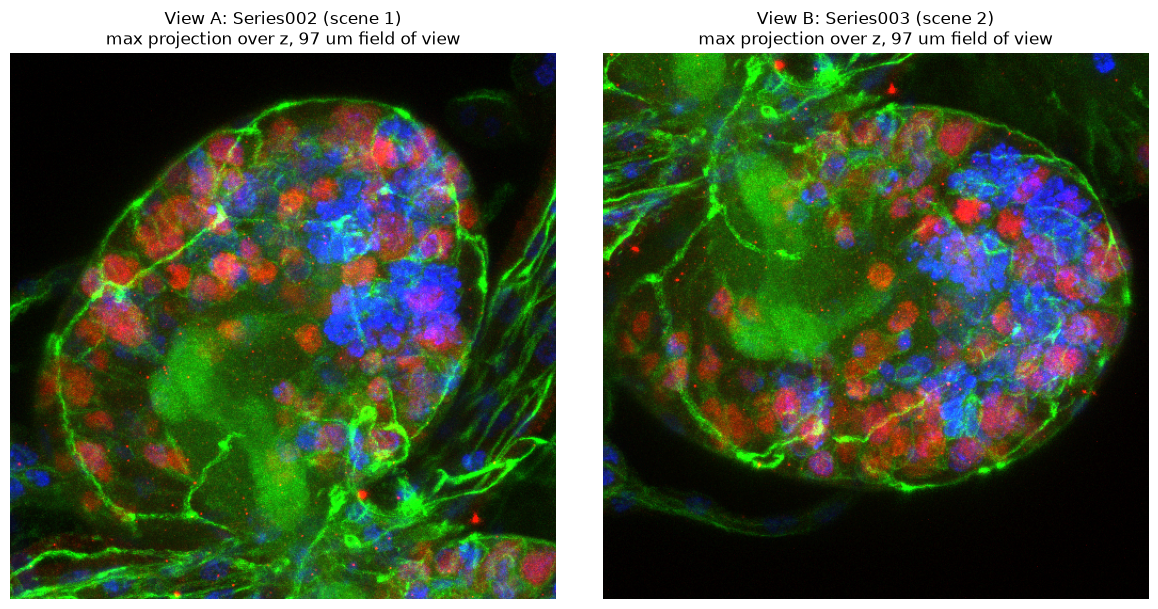

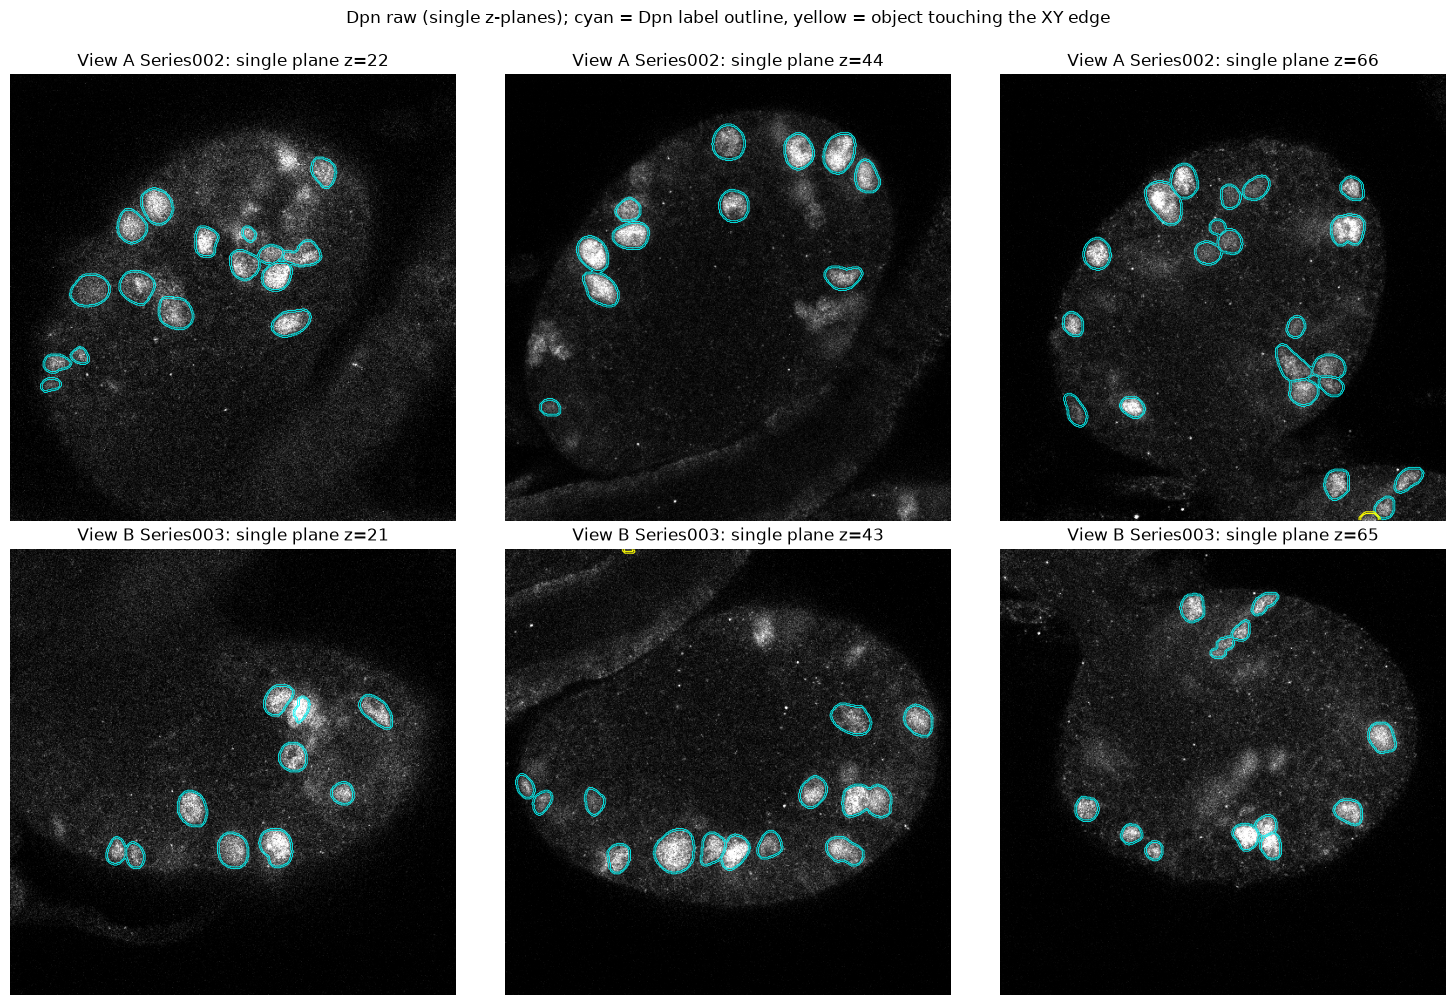

,series,dpn_objects,touching_xy_edge,touching_z_end
view,,,,
A,Series002,154,5,1
B,Series003,149,6,1


In [11]:
def stretch(a, lo=1, hi=99.8):
    a = a.astype(float)
    p0, p1 = np.percentile(a, [lo, hi])
    return np.clip((a - p0) / max(p1 - p0, 1e-9), 0, 1)


def rgb_mip(v):
    c = v["CH"]
    return np.stack([stretch(v["img"][c[n]].max(axis=0)) for n in ("Dpn", "Scrib", "EdU")], axis=-1)


fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, vl in zip(axs, ("A", "B")):
    v = views[vl]
    ax.imshow(rgb_mip(v))
    ax.set_title(f"View {vl}: {v['series']} (scene {v['scene_index']})\nmax projection over z, {qc.loc[vl, 'fov_xy_um']:.0f} um field of view")
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for row, vl in zip(axs, ("A", "B")):
    v, nodes = views[vl], nodes_by_view[vl]
    lab = v["labels"]["Dpn"]
    edge_ids = set(nodes.loc[nodes["touches_xy_edge"], "dpn_label"])
    occupied = np.flatnonzero([len(np.unique(s)) > 1 for s in lab])
    zs = [int(occupied[int(q * (len(occupied) - 1))]) for q in (0.25, 0.5, 0.75)]
    for ax, z in zip(row, zs):
        sl = lab[z]
        ax.imshow(stretch(v["img"][v["CH"]["Dpn"], z]), cmap="gray")
        inner = np.where(np.isin(sl, list(edge_ids)), 0, sl)
        edge = np.where(np.isin(sl, list(edge_ids)), sl, 0)
        ax.contour(find_boundaries(inner), levels=[0.5], colors="cyan", linewidths=0.6)
        if edge.any():
            ax.contour(find_boundaries(edge), levels=[0.5], colors="yellow", linewidths=0.8)
        ax.set_title(f"View {vl} {v['series']}: single plane z={z}")
        ax.axis("off")
plt.suptitle("Dpn raw (single z-planes); cyan = Dpn label outline, yellow = object touching the XY edge", y=1.0)
plt.tight_layout()
plt.show()

display(qc[["series", "dpn_objects", "touching_xy_edge", "touching_z_end"]])

## 7. Lobe masks: exact-scene only, and only as a QC check

A lobe mask is used **only if it exists for this exact scene index**. A scene-0 mask is never applied to scene 1 or 2. Even a same-scene mask with matching dimensions is not assumed to be anatomically correct. It is shown over the image and its coverage is reported.

A zoomed view centred on one lobe should mostly fall in **one** mask region. The check flags several substantial regions, or a large share of objects outside every region, as suspicious.

Unless a reliable single-lobe region is established by review, every graph here is labelled **"zoomed-view graph"**, not "lobe graph". Possible contamination from the other lobe is reported via edge-touching objects and the images above.

In [12]:
lobe_report = []
for vl in ("A", "B"):
    v, nodes = views[vl], nodes_by_view[vl]
    path = LOBE_ROOT / f"{PREFIX}.lif" / f"{PREFIX}-scene-{v['scene_index']}.Lobe.tif"
    if not path.exists():
        print(f"View {vl} ({v['series']}, scene {v['scene_index']}): no lobe mask for this exact scene.")
        lobe_report.append({"view": vl, "mask": None})
        continue
    mask = tifffile.imread(path)
    if mask.shape != v["labels"]["Dpn"].shape:
        print(f"View {vl}: {path.name} shape {mask.shape} != {v['labels']['Dpn'].shape}; not used.")
        lobe_report.append({"view": vl, "mask": path.name, "status": "shape mismatch"})
        continue
    lab = v["labels"]["Dpn"]
    def majority(l):
        vals, cnt = np.unique(mask[lab == l], return_counts=True)
        return int(vals[np.argmax(cnt)])
    region = nodes["dpn_label"].map(majority)
    frac = region.value_counts(normalize=True).sort_index()
    big = [int(r) for r, f in frac.items() if r != 0 and f >= 0.15]
    outside = float(frac.get(0, 0.0))
    flags = []
    if len(big) > 1:
        flags.append(f"{len(big)} regions each hold >=15% of Dpn objects in a single zoomed view")
    if outside > 0.2:
        flags.append(f"{outside:.0%} of Dpn objects lie outside every region")
    print(f"View {vl} ({v['series']}): {path.name}; Dpn fraction by region (0 = outside):",
          {int(k): round(float(f), 3) for k, f in frac.items()})
    print("   SUSPICIOUS: " + "; ".join(flags) if flags else "   No coverage flag raised; still needs visual review.")
    lobe_report.append({"view": vl, "mask": path.name, **{f"frac_region_{int(k)}": float(f) for k, f in frac.items()}, "flags": "; ".join(flags)})

    zmid = int(np.median(nodes["bbox-start-z"] + (nodes["bbox-end-z"] - nodes["bbox-start-z"]) // 2))
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(stretch(v["img"][v["CH"]["Dpn"], zmid]), cmap="gray")
    ax.imshow(np.ma.masked_where(mask[zmid] == 0, mask[zmid]), cmap="tab10", alpha=0.3, vmin=0, vmax=9)
    ax.contour(find_boundaries(mask[zmid]), levels=[0.5], colors="white", linewidths=0.8)
    ax.set_title(f"View {vl}: {path.name} over Dpn, z={zmid}")
    ax.axis("off")
    plt.show()

print("\nGraph label for both views:", {vl: graphs[vl].graph_kind for vl in graphs})

View A (Series002, scene 1): no lobe mask for this exact scene.
View B (Series003, scene 2): no lobe mask for this exact scene.

Graph label for both views: {'A': 'zoomed-view graph', 'B': 'zoomed-view graph'}


## 8. Two edge definitions

- **Symmetrized 5-NN**: each object links to its 5 nearest objects (µm), then links are made mutual. Every node has degree ≥ 5 whatever the local density, so degree mostly reflects how often a node is someone else's neighbour.
- **Radius**: link every pair whose centroid distance is ≤ `RADIUS_UM`. This is symmetric by definition. Degree follows local density, isolated nodes can occur, and the edge count changes sharply with the radius.

The adjacency matrices therefore differ. In dense areas the radius graph has more than 5 links per node; in sparse areas it has fewer, possibly none, while kNN still reaches out to distant objects. Both are proximity edges between objects **within one series**: the two views are separate graphs and no edge crosses between them.

view,A,B
knn_edges,476.000,465.000
knn_deg_mean,6.182,6.242
knn_deg_median,6.000,6.000
knn_deg_max,10.000,10.000
knn_isolated,0.000,0.000
knn_density,0.040,0.042
radius_edges,543.000,502.000
radius_deg_mean,7.052,6.738
radius_deg_median,7.000,6.000
radius_deg_max,17.000,16.000


View A: kNN matches scipy: True | radius matches scipy: True | directed edges in both: 838, kNN only: 114, radius only: 248
View B: kNN matches scipy: True | radius matches scipy: True | directed edges in both: 780, kNN only: 150, radius only: 224
No edge joins different series: each graph only contains nodes of its own series (checked).


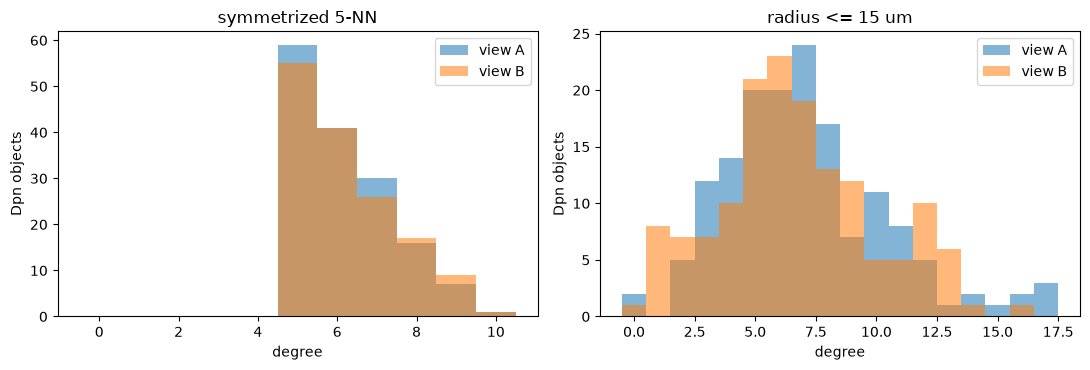

In [13]:
from scipy.spatial import cKDTree

edge_cols = [c for c in qc.columns if c.startswith(("knn_", "radius_"))]
display(qc[edge_cols].T.round(3))

for vl, g in graphs.items():
    p = g.pos.numpy()
    n = g.num_nodes
    _, idx = cKDTree(p).query(p, k=K_NEIGHBORS + 1)
    ref_knn = coalesce(to_undirected(torch.as_tensor(np.stack([np.repeat(np.arange(n), K_NEIGHBORS), idx[:, 1:].ravel()])), num_nodes=n), num_nodes=n)
    pairs = cKDTree(p).query_pairs(RADIUS_UM, output_type="ndarray")
    ref_rad = coalesce(to_undirected(torch.as_tensor(pairs.T.astype(np.int64)), num_nodes=n), num_nodes=n)
    a = set(map(tuple, g.edge_index.T.tolist()))
    b = set(map(tuple, g.radius_edge_index.T.tolist()))
    print(f"View {vl}: kNN matches scipy: {torch.equal(ref_knn, g.edge_index)} | radius matches scipy: {torch.equal(ref_rad, g.radius_edge_index)}"
          f" | directed edges in both: {len(a & b)}, kNN only: {len(a - b)}, radius only: {len(b - a)}")
    assert set(g.node_uid) == set(nodes_by_view[vl]["node_uid"]) and all(u.split("|")[1] == g.series for u in g.node_uid)
print("No edge joins different series: each graph only contains nodes of its own series (checked).")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, title in zip(axs, ("edge_index", "radius_edge_index"), (f"symmetrized {K_NEIGHBORS}-NN", f"radius <= {RADIUS_UM:g} um")):
    for vl, color in (("A", "tab:blue"), ("B", "tab:orange")):
        g = graphs[vl]
        deg = torch.bincount(g[key][0], minlength=g.num_nodes).numpy()
        ax.hist(deg, bins=np.arange(deg.max() + 2) - 0.5, alpha=0.55, color=color, label=f"view {vl}")
    ax.set_xlabel("degree"); ax.set_ylabel("Dpn objects"); ax.set_title(title); ax.legend()
plt.tight_layout()
plt.show()

## 9. Descriptive comparison of view A and view B

**EdU rule (both views):** a Dpn object is EdU+ if any predicted EdU object has 3D IoS > 0.5 with it. IoS is the intersection divided by the volume of the *smaller* object, so a small EdU object mostly inside a Dpn object counts. EdU status is an observed attribute and is **not** in the node features `x`.

How the measurement itself can drive each comparison:
- **Dpn and EdU+ counts** depend on how much of the lobe the field of view and z-range cover, on objects cut by the edge, and on segmentation recall (about 0.57 overall against the 2D ground truth, and it varies by animal and depth).
- **EdU+ fraction** is more robust to coverage than counts, but still depends on which part of the lobe is imaged and on EdU segmentation, which has no ground truth.
- **Volume** is biased low for objects truncated at image edges, and depends on how MicroSAM draws boundaries (predicted cells are larger than manual ones in 2D).
- **Nearest-neighbour distance and degree** are inflated where missed cells leave gaps, and nodes at the image edge lose neighbours outside the field of view.

This is one animal. A difference between A and B here is not a biological finding.

view,A,B
series,Series002,Series003
dpn_objects,154,149
edu_pos,57,54
edu_pos_frac,0.37013,0.362416
touching_xy_edge,5,6
volume_median_um3,140.311343,148.94032
nn_dist_median_um,6.40423,6.433213
knn_deg_mean,6.181818,6.241611
radius_deg_mean,7.051948,6.738255
radius_isolated,2,1


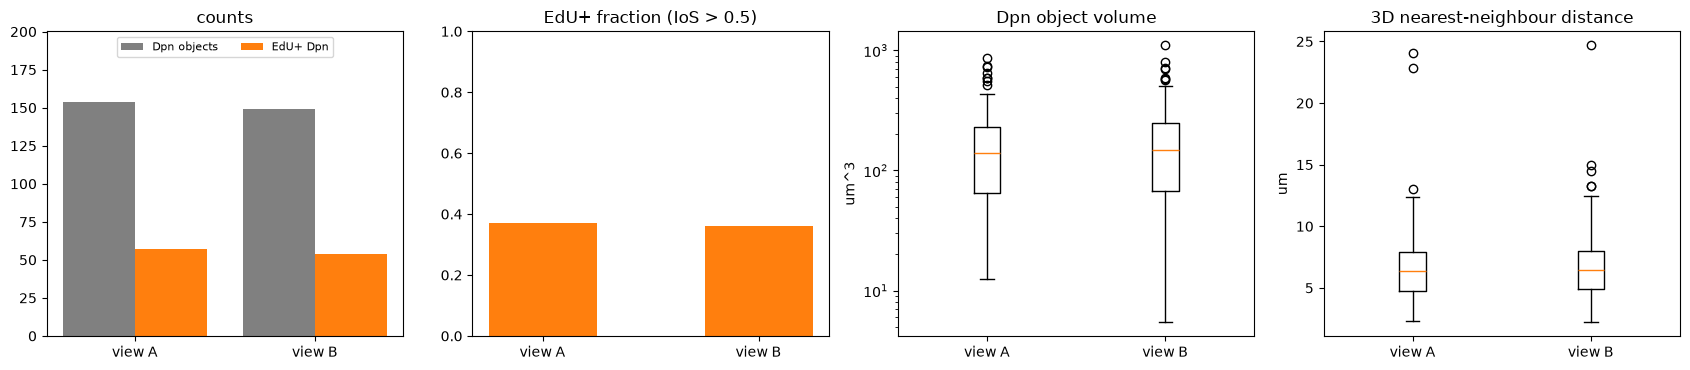

Same comparison excluding objects that touch the XY image edge:


,A,B
dpn_objects,149.000000,143.000000
edu_pos_frac,0.369128,0.363636
volume_median_um3,141.797845,151.768301


In [14]:
summary_cols = ["series", "dpn_objects", "edu_pos", "edu_pos_frac", "touching_xy_edge", "volume_median_um3",
                "nn_dist_median_um", "knn_deg_mean", "radius_deg_mean", "radius_isolated", "radius_density"]
display(qc[summary_cols].T)

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
x = np.arange(2)
axs[0].bar(x - 0.2, qc["dpn_objects"], 0.4, label="Dpn objects", color="0.5")
axs[0].bar(x + 0.2, qc["edu_pos"], 0.4, label="EdU+ Dpn", color="tab:orange")
axs[0].set_xticks(x, [f"view {vl}" for vl in qc.index]); axs[0].set_ylim(0, qc["dpn_objects"].max() * 1.3)
axs[0].legend(loc="upper center", ncol=2, fontsize=8); axs[0].set_title("counts")
axs[1].bar(x, qc["edu_pos_frac"], 0.5, color="tab:orange"); axs[1].set_xticks(x, [f"view {vl}" for vl in qc.index])
axs[1].set_ylim(0, 1); axs[1].set_title(f"EdU+ fraction (IoS > {EDU_IOS_THRESHOLD})")
axs[2].boxplot([nodes_by_view[vl]["volume"] for vl in qc.index], tick_labels=[f"view {vl}" for vl in qc.index])
axs[2].set_yscale("log"); axs[2].set_ylabel("um^3"); axs[2].set_title("Dpn object volume")
axs[3].boxplot([nnd_by_view[vl] for vl in qc.index], tick_labels=[f"view {vl}" for vl in qc.index])
axs[3].set_ylabel("um"); axs[3].set_title("3D nearest-neighbour distance")
plt.tight_layout()
plt.show()

print("Same comparison excluding objects that touch the XY image edge:")
display(pd.DataFrame({
    vl: {"dpn_objects": int((~n["touches_xy_edge"]).sum()),
         "edu_pos_frac": float(n.loc[~n["touches_xy_edge"], "edu_pos"].mean()),
         "volume_median_um3": float(n.loc[~n["touches_xy_edge"], "volume"].median())}
    for vl, n in nodes_by_view.items()
}))

## 10. Which view has manual Dpn ground truth?

Andy's manifest maps each annotated slice to a batch series. That view gets its existing F1 results: per-slice and per-animal, with a predicted cell counted as a match when its 2D IoU with a manual cell is ≥ 0.5 (`compute_gt_f1.py` default). The other view has **no manual Dpn ground truth**.

The manual masks are 2D binary planes. They are not used as 3D objects anywhere in this notebook. No "good enough" F1 level has been agreed, so no score is called acceptable here.

In [15]:
manifest_path = require(GT_RESULTS_DIR / "gt_series_manifest.csv", "GT manifest")
manifest = pd.read_csv(manifest_path)
gt = manifest[(manifest["animal_prefix"] == PREFIX) & (manifest["status"] == "OK")]
gt_series = {s.split("-(")[0] for s in gt["best_series"]}
gt_status = {}
for vl, v in views.items():
    has = v["series"] in gt_series
    gt_status[vl] = "manual Dpn slices (Andy's F1 available)" if has else "no manual Dpn ground truth"
    print(f"View {vl} ({v['series']}): {gt_status[vl]}")
overview_has = sel["overview"]["series"] in gt_series
if overview_has or len(gt_series) != 1:
    print("NOTE: manifest maps GT to", gt_series, "- check, expected exactly one zoomed view.")
qc["manual_gt"] = pd.Series(gt_status)

per_slice_path, summary_path = GT_RESULTS_DIR / "f1_per_slice.csv", GT_RESULTS_DIR / "f1_summary.csv"
if per_slice_path.exists() and summary_path.exists():
    ps = pd.read_csv(per_slice_path)
    ps = ps[ps["animal_prefix"] == PREFIX]
    display(ps[["gt_file", "z", "n_gt_cells", "n_pred_cells", "tp", "fp", "fn", "precision", "recall", "f1"]].sort_values("z"))
    display(pd.read_csv(summary_path).query("animal_prefix in [@PREFIX, 'OVERALL']"))
else:
    print("Andy's F1 files not found; ground-truth view identified from the manifest only.")

View A (Series002): no manual Dpn ground truth
View B (Series003): manual Dpn slices (Andy's F1 available)


,gt_file,z,n_gt_cells,n_pred_cells,tp,fp,fn,precision,recall,f1
0,Animal-1-scrib-edu-dpn-scene-2.z-0013.dpn.gt.tif,13,5,8,3,5,2,0.375000,0.600000,0.461538
1,Animal-1-scrib-edu-dpn-scene-2.z-0020.dpn.gt.tif,20,14,11,7,4,7,0.636364,0.500000,0.560000
2,Animal-1-scrib-edu-dpn-scene-2.z-0024.dpn.gt.tif,24,12,9,8,1,4,0.888889,0.666667,0.761905
3,Animal-1-scrib-edu-dpn-scene-2.z-0030.dpn.gt.tif,30,17,17,9,8,8,0.529412,0.529412,0.529412
4,Animal-1-scrib-edu-dpn-scene-2.z-0031.dpn.gt.tif,31,15,16,9,7,6,0.562500,0.600000,0.580645
5,Animal-1-scrib-edu-dpn-scene-2.z-0051.dpn.gt.tif,51,22,23,19,4,3,0.826087,0.863636,0.844444
6,Animal-1-scrib-edu-dpn-scene-2.z-0052.dpn.gt.tif,52,19,20,15,5,4,0.750000,0.789474,0.769231
7,Animal-1-scrib-edu-dpn-scene-2.z-0060.dpn.gt.tif,60,16,12,11,1,5,0.916667,0.687500,0.785714
8,Animal-1-scrib-edu-dpn-scene-2.z-0067.dpn.gt.tif,67,23,17,12,5,11,0.705882,0.521739,0.600000
9,Animal-1-scrib-edu-dpn-scene-2.z-0083.dpn.gt.tif,83,4,4,2,2,2,0.500000,0.500000,0.500000


,animal_prefix,n_slices,tp,fp,fn,precision,recall,f1,mean_per_slice_f1
0,Animal-1-scrib-edu-dpn,10,95,42,52,0.693431,0.646259,0.669014,0.639289
12,OVERALL,120,941,486,698,0.659425,0.574131,0.613829,0.602197


## 11. Save QC table, node tables and paired graphs

In [16]:
qc.to_csv(OUT_DIR / "qc_views.csv")
for vl, n in nodes_by_view.items():
    n.drop(columns=["stack_id", "slice_id"], errors="ignore").to_csv(OUT_DIR / f"nodes_view{vl}_{views[vl]['series']}.csv", index=False)
torch.save(graphs, OUT_DIR / "paired_graphs.pt")
run_info = {
    "animal": ANIMAL, "raw_path": str(sel["raw_path"]),
    "scene_inventory": {"overview": sel["overview"], "A": sel["A"], "B": sel["B"], "visually_confirmed": sel["visually_confirmed"]},
    "series_dirs": {vl: str(v["series_dir"]) for vl, v in views.items()},
    "label_files": {vl: {k: str(p) for k, p in v["label_paths"].items()} for vl, v in views.items()},
    "gt_manifest": str(manifest_path), "manual_gt": gt_status,
    "units": "um; centroids = pixel centroid x |LIF spacing| (LIF Z step is negative)",
    "spacing_zyx_um": {vl: v["spacing_zyx_um"] for vl, v in views.items()},
    "edu_rule": f"Dpn EdU+ if any EdU object has 3D IoS > {EDU_IOS_THRESHOLD}",
    "edges": {"primary": f"symmetrized {K_NEIGHBORS}-NN", "alternative": f"radius <= {RADIUS_UM} um"},
    "node_features": FEATURE_COLS,
    "exclusions": "none; objects touching the XY edge are flagged (touches_xy_edge), not removed",
    "lobe_masks": lobe_report,
    "graph_kind": "zoomed-view graph (no reliable single-lobe region established)",
}
(OUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
reloaded = torch.load(OUT_DIR / "paired_graphs.pt", weights_only=False)
assert all(torch.equal(reloaded[vl].radius_edge_index, graphs[vl].radius_edge_index) for vl in graphs)
print("Saved to", OUT_DIR, ":", sorted(p.name for p in OUT_DIR.iterdir()))

Saved to /home/tqv9uu/vistiqlab/outputs/paired_lobe_graph_pilot/Animal-1-scrib-edu-dpn : ['nodes_viewA_Series002.csv', 'nodes_viewB_Series003.csv', 'paired_graphs.pt', 'qc_views.csv', 'run_info.json']


## 12. Optional: all 12 animals (off by default)

With `RUN_ALL_ANIMALS = True` this runs the same `resolve_views` and `build_view` for animals 1–12, without plots, and writes per-animal graphs plus one combined QC table to `OUT_ROOT/all_animals/`. An animal that fails a check is recorded with its error and skipped, never patched. 

In [17]:
if RUN_ALL_ANIMALS:
    all_dir = OUT_ROOT / "all_animals"
    all_dir.mkdir(parents=True, exist_ok=True)
    rows, failures = [], []
    for animal in sorted(SCENE_INVENTORY):
        try:
            s = resolve_views(animal)
            pair = {}
            for vl in ("A", "B"):
                _, _, g, _, q = build_view(animal, vl, s[vl]["scene_index"], s["raw_path"])
                pair[vl] = g
                rows.append({**q, "visually_confirmed": s["visually_confirmed"]})
            torch.save(pair, all_dir / f"{prefix_for(animal)}_paired_graphs.pt")
            print(f"Animal {animal}: OK")
        except Exception as e:
            failures.append({"animal": animal, "error": f"{type(e).__name__}: {e}"})
            print(f"Animal {animal}: FAILED - {type(e).__name__}: {e}")
    pd.DataFrame(rows).to_csv(all_dir / "qc_views_all_animals.csv", index=False)
    pd.DataFrame(failures, columns=["animal", "error"]).to_csv(all_dir / "failures.csv", index=False)
    display(pd.DataFrame(rows)[["animal", "view", "series", "dpn_objects", "edu_pos_frac", "nn_dist_median_um"]])
else:
    print("RUN_ALL_ANIMALS is False: only Animal", ANIMAL, "was processed.")

Animal 1: OK
Animal 2: OK
Animal 3: OK
Animal 4: OK
Animal 5: OK
Animal 6: OK
Animal 7: OK
Animal 8: OK
Animal 9: OK
Animal 10: OK
Animal 11: OK
Animal 12: OK


,animal,view,series,dpn_objects,edu_pos_frac,nn_dist_median_um
0,1,A,Series002,154,0.370130,6.404230
1,1,B,Series003,149,0.362416,6.433213
2,2,A,Series001,163,0.073620,6.107117
3,2,B,Series002,176,0.051136,5.091496
4,3,A,Series002,161,0.248447,6.106877
5,3,B,Series003,176,0.357955,6.064545
6,4,A,Series001,149,0.053691,6.765679
7,4,B,Series002,166,0.198795,6.288211
8,5,A,Series002,179,0.301676,6.585228
9,5,B,Series003,189,0.269841,6.277051


## 13. What we learned / what remains uncertain

**Learned (for the selected animal):**
- Both zoomed series load and match their batch labels by scene name, shape, channels and spacing. Their centroids are in µm without double scaling.
- Each view gives a valid PyG graph with two edge definitions: symmetric, no self-loops or duplicates, and matching an independent scipy construction.
- The views can be compared on Dpn and EdU+ counts, EdU+ fraction, volume, nearest-neighbour distance and degree. Edge-touching objects show how much each view may include truncated cells or tissue outside the lobe.

**Uncertain:**
- **A/B are not left/right.** "View A" is just the lower zoomed scene index. Without a consistent orientation landmark, A in one animal need not be the same side as A in another. Cross-animal comparisons must be symmetric in A and B, e.g. absolute differences.
- **These are zoomed-view graphs, not lobe graphs.** No reliable single-lobe mask exists for the zoomed scenes, and some views include part of the other lobe or unrelated tissue at the edges.
- **Coverage and segmentation shape every summary.** Field of view, z-range, Dpn recall (manual ground truth exists for only one view per animal) and unvalidated EdU calls all affect them.
- **The inventory for animals 7–12 is provisional** until checked visually.

**Design for later:**
- **12 animals give 12 matched pairs, not 24 independent samples.** Any test should be paired within animal, e.g. differences per animal or a sign-flip permutation across animals.
- **A simple paired similarity baseline before any GNN.** For each animal, compute a vector of the summaries above per view, plus graph statistics such as the degree distribution, nearest-neighbour-distance distribution and EdU+ neighbour fraction. Measure A–B dissimilarity within each animal (e.g. Wasserstein distance between distributions, absolute difference of fractions) and compare it with the dissimilarity between views from *different* animals. If views from the same animal are not more similar than views from different animals by these simple measures, a GNN is unlikely to find meaningful bilateral structure.
- **Do not train a model to tell which animal a graph came from.** Animals differ in imaging session, zoom, mounting, staining and segmentation quality, so such a model can succeed on technical artefacts alone. Calling that "bilateral symmetry" would be wrong. Any learned similarity must beat the simple baseline and be checked against technical covariates (zoom, z-range, F1).